# Laboratorio di Analisi Numerica
## Lezione 4

Cecilia Pagliantini <cecilia.pagliantini@unipi.it>  
Leonardo Robol <leonardo.robol@unipi.it>  
30-31 ottobre 2025

> **Quantità di esercizi:** in questa dispensa ci sono *più esercizi* di quanti uno studente medio riesca a farne durante una lezione di laboratorio, specialmente tenendo conto anche degli esercizi facoltativi. Questo perché è pensata per “tenere impegnati” per tutta la lezione anche quegli studenti che già hanno un solido background di programmazione.
>
> Quindi fate gli esercizi che riuscite, partendo da quelli *non* segnati come facoltativi, e non preoccupatevi se non li finite tutti!

Questa lezione usa `LinearAlgebra`, incluso nella libreria standard di Julia, e il pacchetto grafico `Plots`. Se `Plots` non è ancora installato, eseguite una sola volta `using Pkg; Pkg.add("Plots")` in una cella, quindi riavviate il kernel.

Eseguite le celle dall'alto verso il basso e completate gli esercizi negli spazi predisposti. Le chiamate che dipendono dalle funzioni da scrivere sono commentate: togliete `#` dopo aver definito le funzioni richieste.

In [ ]:
using LinearAlgebra
using Plots

### Esercizio 1

Si scriva una funzione `laplacian(n)` che crea la matrice di dimensione $n\times n$ con elementi uguali a $2$ sulla diagonale e $-1$ sulla sopra- e sotto-diagonale. Per esempio, `laplacian(5)` deve restituire

$$
\begin{pmatrix}
2 & -1 & 0 & 0 & 0\\
-1 & 2 & -1 & 0 & 0\\
0 & -1 & 2 & -1 & 0\\
0 & 0 & -1 & 2 & -1\\
0 & 0 & 0 & -1 & 2
\end{pmatrix}.
$$

Per questa lezione costruite una matrice densa con entrate `Float64`, come nelle matrici MATLAB originali. Potete usare i comandi `zeros` o `diagm` già incontrati nella lezione 2.

In [ ]:
# Scrivete qui la funzione laplacian(n)
# laplacian(5)

## 1. Soluzione di sistemi triangolari

### 1.1. Sistemi triangolari inferiori

Consideriamo il seguente sistema triangolare inferiore:

$$
\begin{pmatrix}
L_{11} & 0 & 0 & 0 & 0\\
L_{21} & L_{22} & 0 & 0 & 0\\
L_{31} & L_{32} & L_{33} & 0 & 0\\
L_{41} & L_{42} & L_{43} & L_{44} & 0\\
L_{51} & L_{52} & L_{53} & L_{54} & L_{55}
\end{pmatrix}
\begin{pmatrix}x_1\\x_2\\x_3\\x_4\\x_5\end{pmatrix}
=
\begin{pmatrix}b_1\\b_2\\b_3\\b_4\\b_5\end{pmatrix}.
$$

Possiamo risolverlo per sostituzione: a ogni passo $i\geq 2$, supponendo di avere calcolato $x_1,\dots,x_{i-1}$, si ha

$$
x_i=\frac{b_i-\sum_{j=1}^{i-1}L_{ij}x_j}{L_{ii}}.
$$

La funzione seguente implementa questa procedura per matrici e termini noti reali, supponendo che gli elementi diagonali siano non nulli. Per $i=1$ il ciclo interno è vuoto.

In [ ]:
function inf_solve(L, b)
    n = size(L, 1)
    x = zeros(n)
    for i = 1:n
        p = b[i]  # accumulatore
        for j = 1:i-1
            p = p - L[i, j] * x[j]
        end
        x[i] = p / L[i, i]
    end
    return x
end

Testiamo la funzione con `L = tril(laplacian(5))` e termine noto `L*y`, dove `y = collect(1.0:5.0)`. Il risultato atteso è il vettore con componenti $1,2,3,4,5$.

**Julia:** `zeros(n)` e `collect(1.0:5.0)` creano vettori monodimensionali, adatti al prodotto matrice-vettore. Non serve trasporli: l'operatore `'` produrrebbe invece un vettore aggiunto, visualizzato come riga. `tril` estrae la parte triangolare inferiore; `triu` quella superiore.

In [ ]:
y = collect(1.0:5.0)
# L = tril(laplacian(5))
# display(L)
# inf_solve(L, L*y)

### Esercizio 2

Scrivere una funzione `sup_solve(U, b)` che risolva un sistema $Ux=b$ con $U$ triangolare superiore (suggerimento: sostituire a partire dall'ultima riga). Testare su `U = triu(laplacian(5))`, `b = U*y` (con `y` vettore opportuno).

**Julia:** per scorrere gli indici dall'ultimo al primo, usate `n:-1:1`; `n:1` ha passo positivo e, per $n>1$, è vuoto.

In [ ]:
# Scrivete qui la funzione sup_solve(U, b) e i test richiesti

### Esercizio 3 (facoltativo)

Modificare `inf_solve` e `sup_solve` in modo da sostituire il ciclo `for` più interno con operazioni su vettori. Chiamate queste nuove funzioni rispettivamente `inf_solve2` e `sup_solve2` e confrontate le performance.

**Julia:** due vettori monodimensionali non si moltiplicano con `v*w`; per sommare i prodotti delle componenti potete usare `sum(v .* w)`. Julia compila anche i cicli, quindi una versione basata su operazioni vettoriali non è necessariamente più veloce. Prima di misurare con `@elapsed`, chiamate ciascuna funzione con gli stessi tipi di argomenti per escludere la compilazione iniziale, come nella lezione 3.

In [ ]:
# Scrivete qui inf_solve2, sup_solve2 e il confronto dei tempi

### 1.2. Soluzione di sistemi con la matrice di Laplace

Il comando `F = lu(A, NoPivot())` calcola la fattorizzazione LU senza scambi di righe. Le matrici `L = F.L` e `U = F.U` sono rispettivamente triangolare inferiore e superiore e soddisfano $LU=A$, a meno degli errori di arrotondamento (maggiori dettagli a lezione!).

**Julia:** `lu` restituisce un oggetto fattorizzazione, da cui estraiamo i fattori. Normalmente `lu(A)` usa il pivoting: in generale `F.L * F.U ≈ A[F.p, :]`, dove `F.p` descrive la permutazione delle righe. Qui usiamo esplicitamente `NoPivot()`, adatto alla matrice di Laplace di questa lezione, per mantenere la relazione $A=LU$ e la struttura dei fattori. Non va esteso senza verifiche a una matrice qualunque.

In [ ]:
# A = laplacian(5)
# F = lu(A, NoPivot())
# L = F.L
# U = F.U
# display(L)
# display(U)
# L * U - A

Per $n=5$ si ottengono, approssimativamente,

$$
L=\begin{pmatrix}
1&0&0&0&0\\
-0.5&1&0&0&0\\
0&-0.66667&1&0&0\\
0&0&-0.75&1&0\\
0&0&0&-0.8&1
\end{pmatrix},\qquad
U=\begin{pmatrix}
2&-1&0&0&0\\
0&1.5&-1&0&0\\
0&0&1.33333&-1&0\\
0&0&0&1.25&-1\\
0&0&0&0&1.2
\end{pmatrix}.
$$

La differenza `L * U - A` è nulla a meno degli errori di arrotondamento.

Utilizzando questa fattorizzazione e le funzioni `inf_solve` e `sup_solve` possiamo scrivere una funzione che risolve un sistema $Ax=b$ con `A = laplacian(5)`: infatti,

$$
Ax=LUx=b\qquad\longrightarrow\qquad
\begin{cases}Ly=b,\\Ux=y.\end{cases}
$$

In [ ]:
function lap_solve(n, b)
    F = lu(laplacian(n), NoPivot())
    L = F.L
    U = F.U
    y = inf_solve(L, b)
    x = sup_solve(U, y)
    return x
end

Testiamo dopo aver completato gli esercizi 1 e 2. Il risultato atteso è di nuovo il vettore con componenti $1,2,3,4,5$, a meno degli errori di arrotondamento:

In [ ]:
# A = laplacian(5)
# y = collect(1.0:5.0)
# lap_solve(5, A*y)

Possiamo testarlo anche su matrici molto più grandi, per esempio per $n=1000$. Nella dispensa MATLAB originale si indicava un tempo inferiore a 20 secondi sui computer del laboratorio; i tempi in Julia dipendono dall'implementazione e dal calcolatore.

**Osservazione:** oggi ci soffermeremo sulla soluzione di sistemi con matrice di Laplace. Notate però che la strategia riportata sopra è applicabile a una qualunque matrice per la quale esista una fattorizzazione LU. Se si usa una fattorizzazione con pivoting, bisogna permutare anche il termine noto: il primo sistema diventa `L*y = b[F.p]`.

### Esercizio 4 (facoltativo)

Qual è l'errore relativo (in norma-2) ottenuto sulla soluzione per diversi valori di $n$? Come è legato al condizionamento della matrice `laplacian(n)`, che potete calcolare usando il comando `cond` di Julia?

Con una soluzione esatta nota `y` e una soluzione calcolata `x`, l'errore relativo è `norm(x - y) / norm(y)`. Per i vettori, `norm` usa per default la norma euclidea; `cond(A)` usa per default la norma-2.

In [ ]:
# Scrivete qui gli esperimenti su errore relativo e condizionamento

### 1.3. Un problema fisico

Vogliamo determinare qual è la forma assunta da una corda (o da un elastico, o da un ponte) su cui sono appoggiati dei carichi. Modellizziamo la corda come una serie di “particelle” $P_0,P_1,P_2,\dots,P_n,P_{n+1}$ disposte a intervalli regolari, a ognuna delle quali è applicato un certo peso. Supponiamo che le coordinate $x_0,y_0$ del punto $P_0$ e le coordinate $x_{n+1},y_{n+1}$ del punto $P_{n+1}$ siano fissate. Supponiamo inoltre che le particelle possano muoversi solo in verticale, cioè che le $x_i$, $1\leq i\leq n$, siano fissate a intervalli regolari.

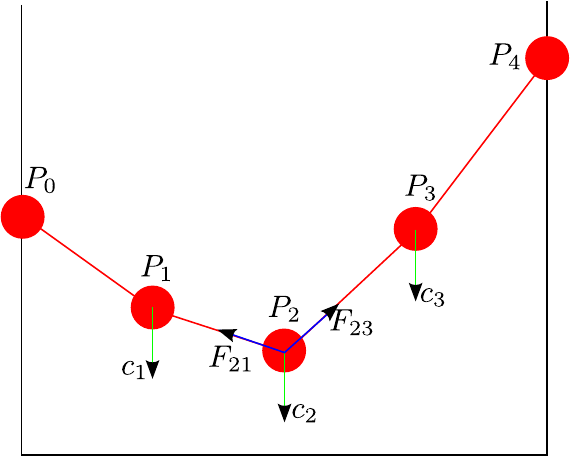

Modello del ponte e forze sulle particelle (figura della dispensa originale).

Su ogni punto $P_i$ *interno* alla corda agiscono tre forze:

- Il carico $c_i$ (verso il basso), che indica quanto peso viene appoggiato sul punto $P_i$.
- La forza $F_{i,i+1}$ che “tiene incollato” il punto al punto alla sua destra; la sua componente verticale è circa uguale a $k(y_{i+1}-y_i)$, per un'opportuna costante elastica $k$.
- La forza $F_{i,i-1}$ che “tiene incollato” il punto al punto alla sua sinistra; la sua componente verticale è circa uguale a $k(y_{i-1}-y_i)$.

L'equilibrio si ha quando $c_i=k(y_{i+1}-y_i)+k(y_{i-1}-y_i)$, o anche

$$
-y_{i-1}+2y_i-y_{i+1}=-c_i/k.
$$

Possiamo scrivere queste equazioni come un sistema lineare $Ly=b$, dove $L$ è la matrice di Laplace vista sopra, $y=(y_1,y_2,\dots,y_n)$ sono le altezze dei punti interni al ponte e, ponendo $k=1$ (tanto dipende solo dalle unità di misura),

$$
b=\begin{bmatrix}
y_0-c_1\\-c_2\\-c_3\\\vdots\\-c_{n-1}\\y_{n+1}-c_n
\end{bmatrix}.
$$

Come mai il primo e l'ultimo termine sono diversi?

Qui $L$ indica la matrice di Laplace, non il fattore triangolare della sezione precedente. Il vettore Julia `y` contiene solo le $n$ altezze interne: $y_0$ e $y_{n+1}$ sono dati separati, non elementi da cercare con gli indici `0` e `n+1` nel vettore.

### Esercizio 5

Ponete $n=20$. Scrivete il termine noto $b$ per i carichi $c_i=1$ per ogni $i$, assumendo $y_0=y_{n+1}=0$. Risolvete il sistema per trovare le altezze dei punti, e disegnate il “ponte” con il comando `plot(1:20, y)`.

Potete usare `lap_solve` e aggiungere al grafico le etichette con `xlabel="i"`, `ylabel="altezza"` e `label=false`.

In [ ]:
# Scrivete qui il termine noto, la soluzione del sistema e il grafico del ponte

### Esercizio 6

Provate a cambiare i carichi aggiungendo dei pesi in punti specifici del ponte. Provate a cambiare le altezze dei due estremi del “ponte”.

In [ ]:
# Inserite qui gli esperimenti con carichi e altezze degli estremi diversi

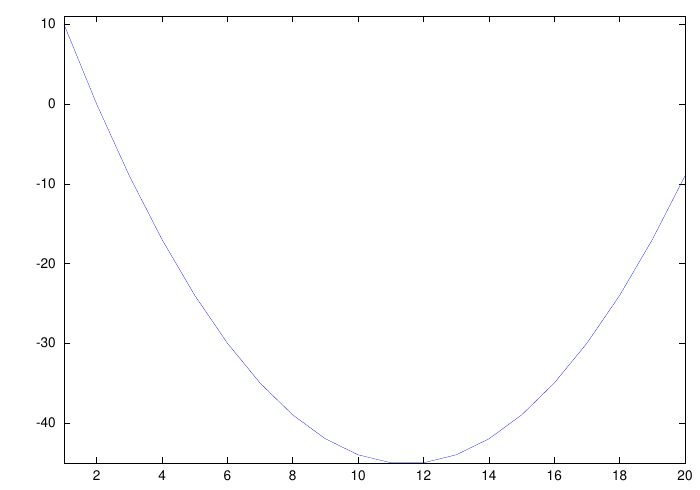

Esempio di profilo del ponte con carichi e altezze degli estremi modificati (grafico della dispensa originale).

## 2. Facoltativo: sfruttare la struttura

### 2.1. Matrici bidiagonali

Notiamo che le matrici $L$ e $U$ per le matrici `laplacian(n)` hanno una struttura particolare: tutti gli elementi sono nulli tranne quelli sulla diagonale principale e sulla sottodiagonale (per $L$) o sopradiagonale (per $U$). $L$ e $U$ sono dette *bidiagonali*. Possiamo sfruttare esplicitamente questo fatto nei nostri algoritmi.

### Esercizio 7 (facoltativo)

Scrivere due funzioni `inf_solve3` e `sup_solve3` che risolvano i sistemi $Ly=b$ e $Ux=y$ supponendo $L$ e $U$ bidiagonali (facendo meno calcoli di `inf_solve` e `sup_solve`!). Poi scrivere la funzione `lap_solve2` analoga a `lap_solve`, ma che utilizzi le due funzioni appena scritte.

In [ ]:
# Scrivete qui inf_solve3, sup_solve3 e lap_solve2

Quanto tempo impiegano le due funzioni? Togliete i commenti dopo averle definite. Le chiamate preliminari escludono la compilazione iniziale dalle misure:

In [ ]:
# b = laplacian(1000) * collect(1.0:1000.0)
# lap_solve(1000, b)
# lap_solve2(1000, b)
# t1 = @elapsed lap_solve(1000, b)
# t2 = @elapsed lap_solve2(1000, b)
# @show t1 t2

Nella dispensa MATLAB originale si ottenevano, rispettivamente, circa 11.669 e 2.1535 secondi. Questi sono valori di riferimento storici: misurate i tempi in Julia sul vostro calcolatore e ripetete le misure.

Il confronto include anche la fattorizzazione LU, che per ora viene calcolata nello stesso modo nelle due funzioni. Mantenete la stessa rappresentazione densa della matrice per confrontare l'effetto delle nuove sostituzioni.

Quando una matrice ha una struttura dobbiamo sempre cercare di sfruttarla nei calcoli; il guadagno di tempo (e a volte anche di precisione dei risultati) può essere notevole.

### Esercizio 8 (facoltativo)

*Esercizio un po' più teorico e lungo, da farsi solo se si è finito tutto il resto.*

Si consideri un sistema lineare $Ax=b$ dove la matrice $A$ è “a banda $k$”, ovvero $A_{ij}=0$ per ogni $i,j$ con $|i-j|>k$. Si supponga di essere nella situazione in cui

$$
|A_{ii}|-\sum_{j\neq i}|A_{ij}|\geq\gamma>0\qquad\text{per ogni }i.
$$

*Nota di trascrizione:* nella dispensa il termine diagonale è scritto $|A_{jj}|$ accanto a una somma sulla riga $i$; qui è corretto in $|A_{ii}|$, rendendo coerenti gli indici della condizione di dominanza diagonale.

1. Si mostri che il sistema è sempre risolubile, i.e., $\det(A)\neq 0$.
2. Si dimostri che se $A=LU$, con $L$ triangolare inferiore e $U$ triangolare superiore, tutti gli elementi diagonali di $L$ ed $U$ sono diversi da zero.
3. Analogamente, si dimostri che $A=LU$, con $L$ triangolare inferiore e $U$ triangolare superiore come sopra (con gli elementi diagonali non nulli), implica che anche $L$ ed $U$ siano a banda $k$.
4. Se ne concluda che, a meno di calcolare $L$ ed $U$, il vettore $x$ si può determinare a partire da $b$ usando al più $\mathcal O(kn)$ operazioni aritmetiche. Le matrici $L$ ed $U$, come vedremo nel prossimo laboratorio, si possono calcolare in $\mathcal O(k^2n)$ operazioni.
5. Si mostri che se $A$ è simmetrica, il numero di condizionamento di $A$ rispetto alla norma spettrale è limitato da $\kappa(A):=\lVert A\rVert_2\lVert A^{-1}\rVert_2\leq\lVert A\rVert_2/\gamma$.
6. Si può dire qualcosa su $\kappa(A)$ se $A$ non è simmetrica, ma è diagonalizzabile?

**Numero di condizionamento:** il numero di condizionamento di un sistema lineare caratterizza l'amplificazione degli errori nella soluzione numerica del sistema. Lavorando con precisione di macchina $u$, la soluzione $x$ viene determinata con un errore relativo limitato da $\kappa(A)\,u$ (a meno di una costante che dipende da $n$ e dall'algoritmo, ma non da $A$).

*Scrivete qui le dimostrazioni e le osservazioni per l’esercizio 8.*

Riferimento per gli adattamenti: [algebra lineare in Julia — fattorizzazioni LU, norme e condizionamento](https://docs.julialang.org/en/v1/stdlib/LinearAlgebra/).